<a href="https://colab.research.google.com/github/LakinduSachin/CR-CM-Coursework/blob/main/CR_%26_CM_Course_work_Draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install yfinance
!pip -q install yfinance

In [ ]:
#Import pandas, numpy, scikit-learn, scipy and matplotlib.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

from datetime import date, datetime
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

# One seed for everything that has a random component, so the notebook is reproducible.
SEED = 42
np.random.seed(SEED)

# Study window from the brief. The end date is EXCLUSIVE, so the last session we keep is in 2024.
START = "2021-01-01"
END   = "2025-01-01"          # exclusive
BENCHMARK = "^GSPC"

# Feature-engineering windows (also from the brief).
VOL_WINDOW = 20               # sessions used for the rolling volume baseline
RFM_WINDOW = 60               # sessions used for Frequency and Monetary
VOL_MULT   = 2.0              # 'high volume' = more than twice the preceding 20-session mean
MIN_HISTORY = 0.80            # a share must trade on at least 80% of sessions to be retained
MIN_WEEKS   = 52             # minimum aligned weekly observations before we trust a beta

RETRIEVAL_DATE = date.today().isoformat()
print("Data retrieval date:", RETRIEVAL_DATE)

Data retrieval date: 2026-11-22


## Task 1 — Data Preparation and Feature Engineering

### 1.1 Ticker selection and data acquisition

I take the constituent list from the Wikipedia S&P 500 page and record the date I pulled it, because
the list changes over time and that date is part of the provenance. Then I download daily data for every
ticker plus the `^GSPC` benchmark over the study window. I keep `auto_adjust=False` on purpose: that
gives me both an adjusted close (which I use for returns and beta, because it already accounts for
splits and dividends) and the raw close and volume (which the adapted RFM needs, since traded value
is raw price times raw volume).

In [ ]:
# Pull the current S&P 500 constituent table from Wikipedia.
# A User-Agent header is needed or Wikipedia returns HTTP 403.
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
sp500_table = pd.read_html(WIKI_URL, storage_options={"User-Agent": "Mozilla/5.0"})[0]

# yfinance expects dashes, not dots, in class-share tickers (e.g. BRK.B -> BRK-B).
sp500_table["Symbol"] = sp500_table["Symbol"].str.replace(".", "-", regex=False)
tickers = sp500_table["Symbol"].tolist()

# Keep the Symbol -> sector / name mapping; Task 3 needs sector composition later.
sector_map = sp500_table.set_index("Symbol")[["Security", "GICS Sector"]]

print(f"Constituents listed on {RETRIEVAL_DATE}: {len(tickers)}")
sp500_table[["Symbol", "Security", "GICS Sector"]].head(10)

Constituents listed on 2026-11-21: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [ ]:
# Download daily OHLCV for all constituents in one call. auto_adjust=False keeps 'Adj Close'
# separate from 'Close', and group_by='column' gives a tidy (field -> ticker) column layout.
raw = yf.download(tickers, start=START, end=END, auto_adjust=False,
                  group_by="column", progress=True, threads=True)

adj_close = raw["Adj Close"].copy()   # for returns and beta
close      = raw["Close"].copy()      # raw close for Monetary (Close x Volume)
volume     = raw["Volume"].copy()     # raw volume for the volume-spike rule

print("Adjusted close panel:", adj_close.shape, "(sessions x tickers)")

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'Q', 'FDXF', 'VYLR', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Adjusted close panel: (1005, 503) (sessions x tickers)


In [ ]:
# Benchmark download, kept on the same calendar. The benchmark is a price index, so its
# weekly returns use its adjusted close just like the shares.
bench_raw = yf.download(BENCHMARK, start=START, end=END, auto_adjust=False, progress=False)
bench_adj = bench_raw["Adj Close"].squeeze()
bench_adj.name = BENCHMARK
print("Benchmark sessions:", bench_adj.shape[0],
      "| first:", bench_adj.index.min().date(), "| last:", bench_adj.index.max().date())

Benchmark sessions: 1005 | first: 2021-01-04 | last: 2024-12-31


In [ ]:
# Preserve the raw snapshots so the exact inputs are reproducible and can live in the GitHub repo.
adj_close.to_csv("snapshot_adj_close.csv")
close.to_csv("snapshot_close.csv")
volume.to_csv("snapshot_volume.csv")
bench_adj.to_frame().to_csv("snapshot_benchmark.csv")

# A lightweight fingerprint of the inputs, so a later run can be checked against this one.
import hashlib
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(adj_close.fillna(0)).values.tobytes()).hexdigest()[:16]
print("Adjusted-close fingerprint:", fingerprint)
print("Saved snapshots: adj_close, close, volume, benchmark")

Adjusted-close fingerprint: d2b30694111a5bec
Saved snapshots: adj_close, close, volume, benchmark


### 1.2 Data validation and alignment

Before trusting anything I check the usual failure modes: duplicate dates, missing values, nonpositive
prices, bad volume, and unequal histories. A share is **retained** only if it trades on at least 80% of
sessions and has no nonpositive adjusted prices or negative volume; everything else goes into an
**exclusion log** with the reason, so the decisions are transparent rather than silent. I deliberately do
**not** forward-fill prices to disguise gaps — filling invents returns that never happened. Weekly
resampling (next section) then puts shares and the benchmark on identical Friday week-labels so returns
are aligned by construction.

**Survivorship bias.** The constituent list is *today's* membership, applied backwards. Shares that were
dropped from the index or delisted during 2021–2024 are simply absent, so the sample is tilted towards
names that survived and generally did well. Any read of the clusters has to carry that caveat: the universe
is conditioned on survival, which flatters average return and understates tail risk.

In [ ]:
# --- Structural checks on the raw panel ---
print("Duplicate dates in index:", adj_close.index.duplicated().any())
print("Date range:", adj_close.index.min().date(), "->", adj_close.index.max().date())
print("Nonpositive adjusted prices (any):", (adj_close.le(0)).to_numpy().sum())
print("Negative volume cells (any):", (volume.lt(0)).to_numpy().sum())
print("Fully empty tickers:", int(adj_close.isna().all().sum()))

Duplicate dates in index: False
Date range: 2021-01-04 -> 2024-12-31
Nonpositive adjusted prices (any): 0
Negative volume cells (any): 0
Fully empty tickers: 5


In [ ]:
def validate_and_clean(adj_close, volume, min_history=MIN_HISTORY):
    """Decide which shares to retain and log the reason for every exclusion.
    Retain = history coverage >= min_history AND no nonpositive adjusted price AND no negative volume."""
    rows = []
    keep = []
    for t in adj_close.columns:
        a = adj_close[t]
        coverage = a.notna().mean()
        reasons = []
        if a.notna().sum() == 0:
            reasons.append("no price history")
        elif coverage < min_history:
            reasons.append(f"history {coverage:.0%} < {min_history:.0%}")
        if (a.dropna() <= 0).any():
            reasons.append("nonpositive adjusted price")
        if (volume[t].dropna() < 0).any():
            reasons.append("negative volume")
        status = "excluded" if reasons else "retained"
        if status == "retained":
            keep.append(t)
        rows.append({"Share": t, "Status": status, "Coverage": round(coverage, 4),
                     "Reason": "; ".join(reasons)})
    log = pd.DataFrame(rows).set_index("Share").sort_values(["Status", "Coverage"])
    return keep, log

keep, exclusion_log = validate_and_clean(adj_close, volume)
print(f"Retained {len(keep)} of {adj_close.shape[1]} shares")
exclusion_log[exclusion_log.Status == "excluded"]

Retained 492 of 503 shares


,Status,Coverage,Reason
Share,,,
FDXF,excluded,0.0000,no price history
HONA,excluded,0.0000,no price history
Q,excluded,0.0000,no price history
SNDK,excluded,0.0000,no price history
VYLR,excluded,0.0000,no price history
GEV,excluded,0.1920,history 19% < 80%
SOLV,excluded,0.1930,history 19% < 80%
RDDT,excluded,0.1960,history 20% < 80%
VLTO,excluded,0.3114,history 31% < 80%


In [ ]:
# Restrict every panel to the retained shares. From here on these are 'the shares'.
adj_close = adj_close[keep]
close      = close[keep]
volume     = volume[keep]
sector_map = sector_map.loc[sector_map.index.intersection(keep)]
print("Working panels restricted to retained shares:", adj_close.shape)

Working panels restricted to retained shares: (1005, 492)


### 1.3 Weekly return and weekly beta

#### 1.3.1 Mean weekly return

I resample the daily **adjusted** close to Friday-ending weeks and take the last available price in each
week. The weekly return is then

> weekly return = (adjusted close at end of this week ÷ adjusted close at end of the preceding week) − 1.

I drop the first and last week of the window because they straddle the study boundary and are incomplete;
ordinary holiday-shortened weeks (a four-day week around a public holiday) are kept, since they are still
a full *weekly* observation. The **arithmetic mean** weekly return across the window is the return feature
used later for clustering.

In [ ]:
def weekly_returns(adj_close_wide):
    """Daily adjusted close -> Friday-week last price -> simple weekly return.
    First and last (incomplete) weeks are trimmed; missing weeks are left missing, not filled."""
    prices = adj_close_wide.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()
    weekly_price = prices.resample("W-FRI").last()
    weekly_price = weekly_price.iloc[1:-1]                     # trim incomplete boundary weeks
    return weekly_price.pct_change(fill_method=None).iloc[1:]  # first diff row is NaN by construction

weekly_ret = weekly_returns(adj_close)

# Same treatment for the benchmark, so the week labels line up exactly.
bench_week_price = bench_adj.copy()
bench_week_price.index = pd.to_datetime(bench_week_price.index)
bench_week_price = bench_week_price.sort_index().resample("W-FRI").last().iloc[1:-1]
bench_weekly_ret = bench_week_price.pct_change(fill_method=None).iloc[1:]

mean_weekly_return = weekly_ret.mean(axis=0, skipna=True).rename("MeanWeeklyReturn")
print("Weekly return matrix:", weekly_ret.shape, "(weeks x shares)")
mean_weekly_return.describe().round(5)

Weekly return matrix: (206, 492) (weeks x shares)


,MeanWeeklyReturn
count,492.00000
mean,0.00291
std,0.00268
min,-0.00427
25%,0.00133
50%,0.00275
75%,0.00425
max,0.01779


#### 1.3.2 Weekly beta

Weekly beta is

> beta = covariance(share weekly return, benchmark weekly return) ÷ variance(benchmark weekly return),

computed on the **aligned, non-missing** weeks only. I report the number of aligned weekly observations
per share so the reader can see how much data each beta rests on, and I require at least `MIN_WEEKS`
aligned weeks before reporting a beta at all. Missing weeks are never filled, and I never treat a
multi-week gap as a single one-week return.

In [ ]:
def weekly_beta(weekly_ret, bench_weekly_ret, min_weeks=MIN_WEEKS):
    """Per share: beta vs benchmark on aligned weeks, plus the count of aligned observations."""
    out = []
    for s in weekly_ret.columns:
        paired = pd.concat([weekly_ret[s].rename("s"), bench_weekly_ret.rename("m")], axis=1)
        paired = paired.replace([np.inf, -np.inf], np.nan).dropna()
        var_m = paired["m"].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and var_m > 0:
            beta = paired["s"].cov(paired["m"]) / var_m
        out.append({"Share": s, "Beta": beta, "AlignedWeeks": len(paired)})
    return pd.DataFrame(out).set_index("Share")

beta_df = weekly_beta(weekly_ret, bench_weekly_ret)
print("Aligned weekly observations: min %d, max %d" %
      (beta_df.AlignedWeeks.min(), beta_df.AlignedWeeks.max()))
beta_df.describe().round(3)

Aligned weekly observations: min 178, max 206


,Beta,AlignedWeeks
count,492.000,492.000
mean,0.985,205.882
std,0.423,1.518
min,0.055,178.000
25%,0.674,206.000
50%,0.960,206.000
75%,1.186,206.000
max,3.793,206.000


### 1.4 Adapted RFM

The **observation date** is the final trading session that every retained share shares in common — the
last completed common date in the window. Frequency and Monetary look back over the latest `RFM_WINDOW`
(60) sessions ending on that date; Recency looks over the share's whole valid history.

An **unusually high volume day** has volume greater than `VOL_MULT` (twice) the mean volume of the
preceding `VOL_WINDOW` (20) sessions, *excluding the day being tested*. The baseline is a rolling mean
of the previous 20 sessions, computed separately for every share and every day — so the threshold is
`volume.shift(1).rolling(20).mean() * 2`. Worked check from the brief: if the preceding 20-session mean is
1 million, the threshold is 2 million, so 2.5 million qualifies and 1.8 million does not.

In [ ]:
# The observation date = last session on which ALL retained shares have a price.
observation_date = adj_close.dropna(how="any").index.max()
print("Observation date:", observation_date.date())

Observation date: 2024-12-31


In [ ]:
def high_volume_flags(volume_series, window=VOL_WINDOW, mult=VOL_MULT):
    """A day is 'high volume' if volume > mult x mean volume of the preceding `window` sessions
    (the current day is excluded from its own baseline via shift(1))."""
    baseline = volume_series.shift(1).rolling(window).mean()
    threshold = mult * baseline
    flag = volume_series > threshold
    flag[threshold.isna()] = False          # undefined until a full baseline exists
    return flag, threshold

def adapted_rfm(close, volume, observation_date,
                vol_window=VOL_WINDOW, rfm_window=RFM_WINDOW, mult=VOL_MULT):
    """R = calendar days from the latest high-volume day to the observation date (NaN if none);
       F = number of high-volume days in the latest 60 sessions;
       M = sum of Close x Volume over the latest 60 sessions (USD)."""
    obs = pd.Timestamp(observation_date)
    rows = []
    for t in close.columns:
        c = close[t].dropna()
        v = volume[t].reindex(c.index)
        c = c[c.index <= obs]; v = v[v.index <= obs]
        if len(c) < rfm_window + vol_window:
            rows.append({"Share": t, "Recency": np.nan, "Frequency": np.nan,
                         "Monetary": np.nan, "Note": "insufficient history"})
            continue
        flag, _ = high_volume_flags(v, vol_window, mult)
        events = flag[flag].index
        # Recency in CALENDAR days (weekends and holidays included); NaN, never 0, if no event exists.
        recency = np.nan if len(events) == 0 else (obs.normalize() - events[-1].normalize()).days
        last60 = c.index[-rfm_window:]
        frequency = int(flag.reindex(last60).fillna(False).sum())
        monetary  = float((c.reindex(last60) * v.reindex(last60)).sum())
        rows.append({"Share": t, "Recency": recency, "Frequency": frequency,
                     "Monetary": monetary, "Note": ""})
    return pd.DataFrame(rows).set_index("Share")

rfm = adapted_rfm(close, volume, observation_date)
print("Shares with no high-volume event (Recency = NaN):", int(rfm.Recency.isna().sum()))
rfm.head(10)

Shares with no high-volume event (Recency = NaN): 0


,Recency,Frequency,Monetary,Note
Share,,,,
A,11,2,1.400180e+10,
AAPL,11,2,6.233034e+11,
ABBV,11,3,6.837054e+10,
ABNB,11,3,3.652850e+10,
ABT,11,1,3.523027e+10,
ACGL,11,4,1.196213e+10,
ACN,11,2,5.199430e+10,
ADBE,18,3,1.030403e+11,
ADI,36,1,3.849918e+10,


### 1.5 Metric interpretation and supporting evidence

A worked example makes the three measures concrete, so I pick one share and show the actual numbers that
feed R, F and M. I then summarise the feature distributions and restate the validation rules and the
inclusion/exclusion log. These checks support the marks for the calculations above; they are evidence,
not new features.

**What each measure captures, and its limits.** Recency is *how long since this share last traded
abnormally heavily* — a staleness signal, not a value signal. Frequency is *how often it traded heavily
in the last 60 sessions* — an attention/turnover signal. Monetary is *approximate traded value*
(price × volume), which is a liquidity proxy, **not** market capitalisation, profit, or money flowing into
the company. None of the three forecasts return; they describe recent trading behaviour.

In [ ]:
# Worked RFM example for a single share (change EXAMPLE to any retained ticker).
EXAMPLE = rfm.dropna(subset=["Recency"]).index[0]
c = close[EXAMPLE].dropna(); v = volume[EXAMPLE].reindex(c.index)
c = c[c.index <= observation_date]; v = v[v.index <= observation_date]
flag, threshold = high_volume_flags(v)

last_event = flag[flag].index[-1]
last60 = c.index[-RFM_WINDOW:]
print(f"Worked example: {EXAMPLE}  ({sector_map.loc[EXAMPLE, 'Security'] if EXAMPLE in sector_map.index else ''})")
print(f"  Observation date      : {observation_date.date()}")
print(f"  Latest high-volume day : {last_event.date()}  (volume {int(v.loc[last_event]):,} vs "
      f"threshold {threshold.loc[last_event]:,.0f})")
print(f"  Recency  (calendar days): {(observation_date.normalize() - last_event.normalize()).days}")
print(f"  Frequency (last 60 sess): {int(flag.reindex(last60).fillna(False).sum())}")
print(f"  Monetary (sum Close*Vol): ${(c.reindex(last60) * v.reindex(last60)).sum():,.0f}")

Worked example: A  (Agilent Technologies)
  Observation date      : 2024-12-31
  Latest high-volume day : 2024-12-20  (volume 4,363,900 vs threshold 3,896,000)
  Recency  (calendar days): 11
  Frequency (last 60 sess): 2
  Monetary (sum Close*Vol): $14,001,795,716


In [ ]:
# Feature summaries and the validation evidence, side by side.
print("Return / beta feature summary:")
display(pd.concat([mean_weekly_return, beta_df["Beta"]], axis=1).describe().round(4))

print("\nAdapted RFM feature summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

print("\nInclusion / exclusion log (counts):")
display(exclusion_log["Status"].value_counts())

Return / beta feature summary:


,MeanWeeklyReturn,Beta
count,492.0000,492.0000
mean,0.0029,0.9849
std,0.0027,0.4235
min,-0.0043,0.0549
25%,0.0013,0.6737
50%,0.0028,0.9599
75%,0.0042,1.1855
max,0.0178,3.7933



Adapted RFM feature summary:


,Recency,Frequency,Monetary
count,492.00,492.00,4.920000e+02
mean,20.49,3.00,3.974218e+10
std,21.30,1.33,1.286397e+11
min,4.00,0.00,1.297483e+09
25%,11.00,2.00,1.025241e+10
50%,11.00,3.00,1.679667e+10
75%,18.00,4.00,3.253548e+10
max,222.00,8.00,1.847697e+12



Inclusion / exclusion log (counts):


,count
Status,
retained,492
excluded,11


## Task 2 — Stock Segmentation and Sensitivity Analysis

### 2.1 Feature preparation

I build **two separate feature matrices** and fit **two clustering families** to each, giving four baseline
solutions:

| Matrix | Features | Meaning |
|---|---|---|
| Risk–return | mean weekly return, weekly beta | how the share pays off and how it co-moves with the market |
| Trading activity (RFM) | Recency, Frequency, Monetary | how recently / often / heavily it has traded |

Two rules keep the comparison honest. First, both matrices use the **same common valid share set** — the
shares that have a return, a trustworthy beta (enough aligned weeks), *and* a complete R, F, M (Recency is
dropped where no high-volume event exists, because the brief says not to substitute zero). Second, Monetary
is heavily right-skewed, so I apply `log1p` to it and then **standardise each matrix on its own** so no
feature dominates purely because of its units. I report skew before and after so the transform is justified,
not assumed.

In [ ]:
# Common valid share set: return + beta + complete RFM.
valid_rr  = pd.concat([mean_weekly_return, beta_df["Beta"]], axis=1).dropna().index
valid_rfm = rfm.dropna(subset=["Recency", "Frequency", "Monetary"]).index
common_shares = sorted(set(valid_rr) & set(valid_rfm))
print(f"Common valid shares used for all four clustering solutions: {len(common_shares)}")

# Risk-return matrix (original units) and RFM matrix (original units).
rr_raw  = pd.concat([mean_weekly_return, beta_df["Beta"]], axis=1).loc[common_shares]
rr_raw.columns = ["MeanWeeklyReturn", "Beta"]
rfm_raw = rfm.loc[common_shares, ["Recency", "Frequency", "Monetary"]].copy()

Common valid shares used for all four clustering solutions: 492


In [ ]:
# Skew before transformation. Monetary is the obvious offender.
print("Skew (raw):")
print(pd.concat([rr_raw, rfm_raw], axis=1).skew().round(2))

# log1p tames Monetary's right tail; R and F are left as-is and discussed in the report.
rfm_trans = rfm_raw.copy()
rfm_trans["Monetary"] = np.log1p(rfm_trans["Monetary"])
print("\nMonetary skew: raw %.2f -> log1p %.2f" %
      (rfm_raw["Monetary"].skew(), rfm_trans["Monetary"].skew()))

# Standardise EACH matrix on its own scaler.
rr_scaler, rfm_scaler = StandardScaler(), StandardScaler()
X_rr  = rr_scaler.fit_transform(rr_raw)
X_rfm = rfm_scaler.fit_transform(rfm_trans)
X_rr  = pd.DataFrame(X_rr,  index=common_shares, columns=rr_raw.columns)
X_rfm = pd.DataFrame(X_rfm, index=common_shares, columns=rfm_trans.columns)
print("\nStandardised matrices:", X_rr.shape, "and", X_rfm.shape)

Skew (raw):
MeanWeeklyReturn     0.93
Beta                 1.25
Recency              3.62
Frequency            0.42
Monetary            11.67
dtype: float64

Monetary skew: raw 11.67 -> log1p 1.07

Standardised matrices: (492, 2) and (492, 3)


### 2.2 Agglomerative clustering (Ward)

Ward linkage with Euclidean distance on the standardised features, one dendrogram per matrix. Ward tends to
produce compact, similar-sized clusters, which suits a first segmentation, but it assumes roughly spherical
groups and is sensitive to scaling — hence the standardisation above. I scan cluster counts from 2 to 8 and
choose using **silhouette score, cluster sizes and whether the profiles are interpretable**, not the colour
threshold the dendrogram happens to draw (that colour cut is cosmetic and does not define the number of
groups).

In [ ]:
def ward_scan(X, krange=range(2, 9)):
    """Return the Ward linkage plus a table of silhouette and cluster sizes for k = 2..8."""
    Z = linkage(X, method="ward")
    rows = []
    for k in krange:
        labels = fcluster(Z, t=k, criterion="maxclust")
        rows.append({"k": k,
                     "silhouette": round(silhouette_score(X, labels), 3),
                     "sizes": np.bincount(labels - 1).tolist()})
    return Z, pd.DataFrame(rows).set_index("k")

Z_rr,  ward_rr  = ward_scan(X_rr)
Z_rfm, ward_rfm = ward_scan(X_rfm)
print("Risk-return — Ward scan:"); display(ward_rr)
print("RFM — Ward scan:");          display(ward_rfm)

Risk-return — Ward scan:


,silhouette,sizes
k,,
2,0.332,"[305, 187]"
3,0.331,"[305, 124, 63]"
4,0.333,"[305, 124, 57, 6]"
5,0.273,"[107, 198, 124, 57, 6]"
6,0.301,"[107, 148, 50, 124, 57, 6]"
7,0.309,"[107, 148, 50, 28, 96, 57, 6]"
8,0.308,"[107, 148, 50, 28, 33, 63, 57, 6]"


RFM — Ward scan:


,silhouette,sizes
k,,
2,0.358,"[93, 399]"
3,0.307,"[93, 147, 252]"
4,0.292,"[93, 147, 43, 209]"
5,0.311,"[83, 10, 147, 43, 209]"
6,0.320,"[83, 10, 20, 127, 43, 209]"
7,0.298,"[83, 10, 20, 127, 43, 66, 143]"
8,0.304,"[83, 10, 20, 57, 70, 43, 66, 143]"


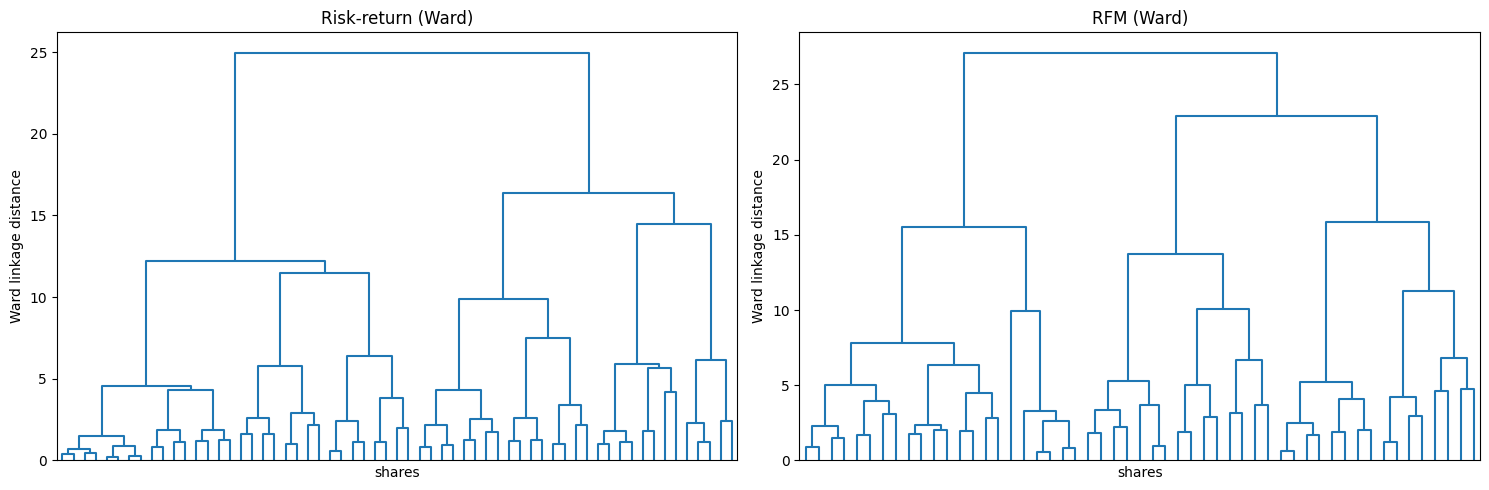

In [ ]:
# One dendrogram per matrix.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, Z, title in [(axes[0], Z_rr, "Risk-return (Ward)"), (axes[1], Z_rfm, "RFM (Ward)")]:
    dendrogram(Z, truncate_mode="level", p=5, ax=ax, no_labels=True, color_threshold=0)
    ax.set_title(title); ax.set_xlabel("shares"); ax.set_ylabel("Ward linkage distance")
plt.tight_layout(); plt.savefig("dendrograms.png", dpi=150); plt.show()

In [ ]:
# Choose a cluster count for each matrix from the scan (highest silhouette with usable sizes).
K_RR  = int(ward_rr["silhouette"].idxmax())
K_RFM = int(ward_rfm["silhouette"].idxmax())
print(f"Selected Ward cluster counts -> risk-return: k={K_RR}, RFM: k={K_RFM}")

ward_rr_labels  = pd.Series(fcluster(Z_rr,  t=K_RR,  criterion="maxclust"), index=common_shares, name="Ward_RR")
ward_rfm_labels = pd.Series(fcluster(Z_rfm, t=K_RFM, criterion="maxclust"), index=common_shares, name="Ward_RFM")

Selected Ward cluster counts -> risk-return: k=4, RFM: k=2


### 2.3 K-means clustering

K-means on the same two standardised matrices, with a fixed seed and multiple initialisations
(`n_init=10`) so the result is stable rather than a lucky/unlucky start. K-means minimises within-cluster
variance and so, like Ward, leans towards spherical, comparably-sized clusters; it can be pulled around by
outliers, which is another reason Monetary was log-transformed. I compare k from 2 to 8 on **silhouette,
inertia (the elbow) and cluster sizes**.

In [ ]:
def kmeans_scan(X, krange=range(2, 9), seed=SEED, n_init=10):
    rows = []
    for k in krange:
        km = KMeans(n_clusters=k, random_state=seed, n_init=n_init).fit(X)
        rows.append({"k": k,
                     "silhouette": round(silhouette_score(X, km.labels_), 3),
                     "inertia": round(km.inertia_, 1),
                     "sizes": np.bincount(km.labels_).tolist()})
    return pd.DataFrame(rows).set_index("k")

km_rr  = kmeans_scan(X_rr)
km_rfm = kmeans_scan(X_rfm)
print("Risk-return — K-means scan:"); display(km_rr)
print("RFM — K-means scan:");          display(km_rfm)

Risk-return — K-means scan:


,silhouette,inertia,sizes
k,,,
2,0.392,626.3,"[143, 349]"
3,0.322,473.5,"[211, 160, 121]"
4,0.327,373.1,"[129, 175, 149, 39]"
5,0.333,315.8,"[172, 26, 127, 110, 57]"
6,0.328,262.8,"[113, 115, 45, 155, 57, 7]"
7,0.340,223.5,"[80, 47, 75, 149, 38, 96, 7]"
8,0.359,193.6,"[45, 139, 30, 50, 76, 75, 71, 6]"


RFM — K-means scan:


,silhouette,inertia,sizes
k,,,
2,0.421,1082.8,"[422, 70]"
3,0.324,810.8,"[154, 275, 63]"
4,0.340,619.2,"[122, 60, 95, 215]"
5,0.357,523.1,"[69, 89, 201, 11, 122]"
6,0.345,446.8,"[119, 67, 106, 143, 42, 15]"
7,0.348,392.3,"[119, 106, 42, 70, 11, 143, 1]"
8,0.342,347.6,"[148, 48, 89, 21, 106, 11, 68, 1]"


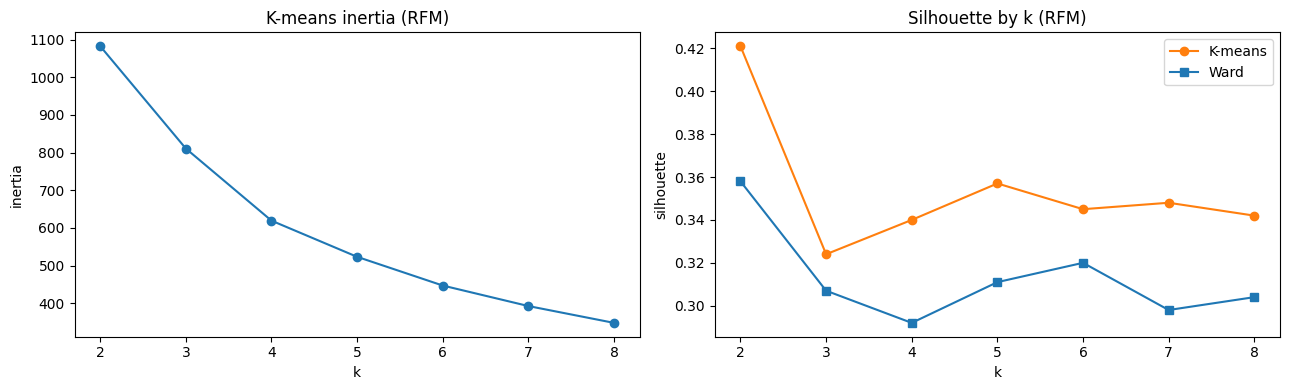

In [ ]:
# Elbow (inertia) + silhouette side by side for the RFM matrix, as an example diagnostic.
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(km_rfm.index, km_rfm["inertia"], marker="o"); ax[0].set(title="K-means inertia (RFM)", xlabel="k", ylabel="inertia")
ax[1].plot(km_rfm.index, km_rfm["silhouette"], marker="o", color="tab:orange")
ax[1].plot(ward_rfm.index, ward_rfm["silhouette"], marker="s", label="Ward")
ax[1].set(title="Silhouette by k (RFM)", xlabel="k", ylabel="silhouette"); ax[1].legend(["K-means", "Ward"])
plt.tight_layout(); plt.show()

# Fit the chosen k (reuse the Ward choice so the two algorithms are compared on the same k).
km_rr_final  = KMeans(n_clusters=K_RR,  random_state=SEED, n_init=10).fit(X_rr)
km_rfm_final = KMeans(n_clusters=K_RFM, random_state=SEED, n_init=10).fit(X_rfm)
kmeans_rr_labels  = pd.Series(km_rr_final.labels_ + 1,  index=common_shares, name="KMeans_RR")
kmeans_rfm_labels = pd.Series(km_rfm_final.labels_ + 1, index=common_shares, name="KMeans_RFM")

### 2.4 Cluster profiles and algorithm comparison

Profiles are reported in **original units** (not the standardised values), because "mean weekly return of
0.3%" and "traded value of \$2.1bn" are interpretable while a z-score is not. For the 2-D picture I use PCA
on the standardised features purely to project onto two axes for plotting — PCA is a *view*, not a new
model, and the axes are linear combinations of the inputs, so cluster shapes on the plot can look distorted
relative to the true high-dimensional distances. Finally I compare the two algorithms on the **same shares**
with a cross-tabulation and the adjusted Rand index (which ignores arbitrary label numbering).

In [ ]:
# Assemble all four baseline solutions into one assignment table.
assignments = pd.concat([ward_rr_labels, kmeans_rr_labels, ward_rfm_labels, kmeans_rfm_labels], axis=1)
assignments.index.name = "Share"

def profile(labels, raw_features):
    """Mean of each original-unit feature per cluster, plus cluster size."""
    g = raw_features.join(labels)
    out = g.groupby(labels.name).mean().round(4)
    out["Size"] = g.groupby(labels.name).size()
    return out

print("Risk-return profiles (Ward), original units:"); display(profile(ward_rr_labels, rr_raw))
print("RFM profiles (Ward), original units:");          display(profile(ward_rfm_labels, rfm_raw))

Risk-return profiles (Ward), original units:


,MeanWeeklyReturn,Beta,Size
Ward_RR,,,
1,0.0017,0.8079,305
2,0.0057,1.0522,124
3,0.0024,1.6231,57
4,0.0126,2.5274,6


RFM profiles (Ward), original units:


,Recency,Frequency,Monetary,Size
Ward_RFM,,,,
1,55.5269,2.0753,4.568673e+10,93
2,12.3283,3.2105,3.835661e+10,399


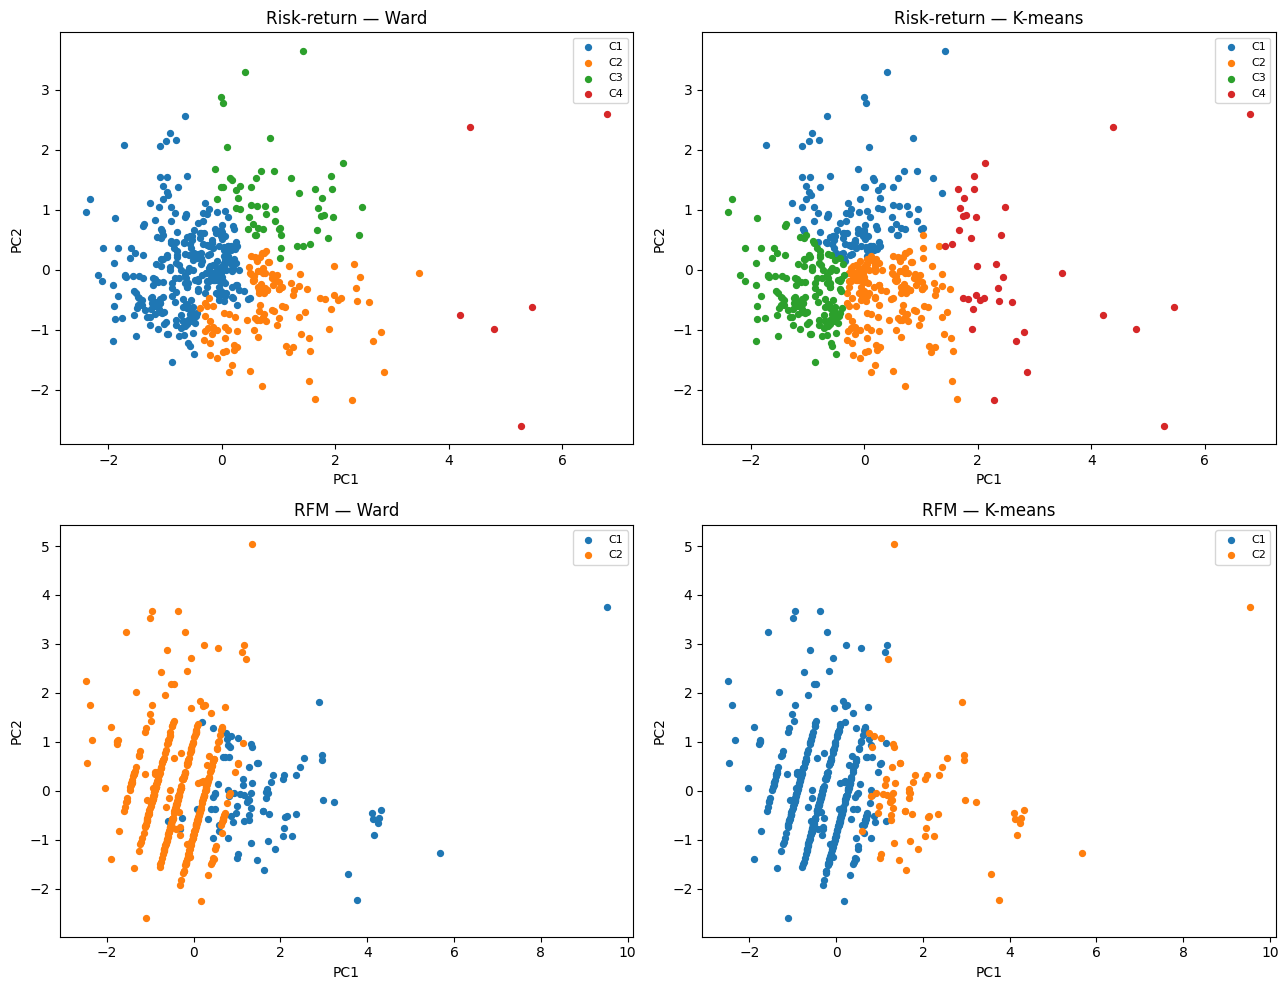

In [ ]:
# Labelled 2-D PCA projections for the four solutions.
def pca_plot(ax, X, labels, title):
    pcs = PCA(n_components=2, random_state=SEED).fit_transform(X)
    for g in np.unique(labels):
        m = labels.values == g
        ax.scatter(pcs[m, 0], pcs[m, 1], s=18, label=f"C{g}")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
pca_plot(ax[0,0], X_rr,  ward_rr_labels,   "Risk-return — Ward")
pca_plot(ax[0,1], X_rr,  kmeans_rr_labels, "Risk-return — K-means")
pca_plot(ax[1,0], X_rfm, ward_rfm_labels,  "RFM — Ward")
pca_plot(ax[1,1], X_rfm, kmeans_rfm_labels,"RFM — K-means")
plt.tight_layout(); plt.savefig("cluster_scatter.png", dpi=150); plt.show()

In [ ]:
# Algorithm agreement on the same shares.
print("Risk-return: Ward vs K-means")
display(pd.crosstab(ward_rr_labels, kmeans_rr_labels))
print("ARI (risk-return):", round(adjusted_rand_score(ward_rr_labels, kmeans_rr_labels), 3))
print("\nRFM: Ward vs K-means")
display(pd.crosstab(ward_rfm_labels, kmeans_rfm_labels))
print("ARI (RFM):", round(adjusted_rand_score(ward_rfm_labels, kmeans_rfm_labels), 3))

Risk-return: Ward vs K-means


KMeans_RR,1,2,3,4
Ward_RR,,,,
1,91,66,148,0
2,0,105,1,18
3,38,4,0,15
4,0,0,0,6


ARI (risk-return): 0.251

RFM: Ward vs K-means


KMeans_RFM,1,2
Ward_RFM,,
1,25,68
2,397,2


ARI (RFM): 0.741


### 2.5 RFM sensitivity and correlated inputs

#### 2.5.1 Correlation analysis

If Recency, Frequency and `log1p`(Monetary) are correlated, then even after standardisation the trading-
activity direction they share is effectively counted more than once, which quietly tilts the distances the
clustering uses. A correlation does **not**, by itself, prove that any one feature dominates — it only flags
the possibility, which 2.5.2 then tests directly.

In [ ]:
corr = rfm_trans.rename(columns={"Monetary": "log1p(Monetary)"}).corr().round(3)
print("Correlation among the RFM clustering inputs:")
display(corr)

Correlation among the RFM clustering inputs:


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.339,0.161
Frequency,-0.339,1.000,0.023
log1p(Monetary),0.161,0.023,1.000


#### 2.5.2 Removal of Monetary

The direct test: refit the **selected Ward RFM solution** using only Recency and Frequency, on the same
shares and the same cluster count, **re-standardising the reduced matrix from scratch**. I compare the new
memberships against the full-RFM memberships with the **adjusted Rand index** (which is immune to how the
clusters happen to be numbered), and I compare the clusters' traded-value (Monetary) profiles. If removing
Monetary barely changes the memberships, then Monetary was mostly re-expressing the activity Recency and
Frequency already carry; if it changes them a lot, Monetary is separating shares by liquidity level in its
own right. Either way, traded value is only a liquidity proxy — spread and price impact are not measured.

In [ ]:
# Re-standardise R and F on their own, refit Ward at the SAME k, compare memberships.
X_rf = StandardScaler().fit_transform(rfm_raw[["Recency", "Frequency"]])
Z_rf = linkage(X_rf, method="ward")
rf_labels = pd.Series(fcluster(Z_rf, t=K_RFM, criterion="maxclust"),
                      index=common_shares, name="Ward_RF_only")

ari = adjusted_rand_score(ward_rfm_labels, rf_labels)
print(f"Cluster count held at k={K_RFM}")
print(f"Adjusted Rand index (full RFM vs R,F only): {ari:.3f}")
print("\nMembership agreement:")
display(pd.crosstab(ward_rfm_labels, rf_labels))

# Traded-value profile of each full-RFM cluster (original USD), to see what Monetary was doing.
tv = rfm_raw.join(ward_rfm_labels).groupby("Ward_RFM")["Monetary"].agg(["mean", "median", "count"])
print("\nTraded value (Monetary, USD) by full-RFM Ward cluster:")
display(tv.round(0))

Cluster count held at k=2
Adjusted Rand index (full RFM vs R,F only): 0.953

Membership agreement:


Ward_RF_only,1,2
Ward_RFM,,
1,90,3
2,2,397



Traded value (Monetary, USD) by full-RFM Ward cluster:


,mean,median,count
Ward_RFM,,,
1,4.568673e+10,2.084781e+10,93
2,3.835661e+10,1.548218e+10,399


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## Task 3 — Business Intelligence and Critical Review (supporting outputs)

The written report (separate 2,500-word document) carries the full Task 3 discussion within the word
limits. This section only produces the **evidence** the report points to: the sector composition of the
clusters, and the exported feature-and-assignment table. Nothing here is a claim about future returns or
reduced portfolio risk — the clusters are descriptive summaries of past trading and co-movement.

In [ ]:
# Sector composition of the RFM Ward clusters (Task 3.2.1).
sec = assignments.join(sector_map["GICS Sector"])
print("Sector composition by RFM Ward cluster:")
display(pd.crosstab(sec["Ward_RFM"], sec["GICS Sector"]))

Sector composition by RFM Ward cluster:


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Ward_RFM,,,,,,,,,,,
1,4,10,8,2,14,9,9,20,8,0,9
2,17,37,24,19,62,49,70,54,16,30,21


In [ ]:
# The deliverable feature table: one row per included share, every feature + all four cluster labels.
feature_table = (pd.concat([mean_weekly_return, beta_df["Beta"], rfm[["Recency","Frequency","Monetary"]]], axis=1)
                 .loc[common_shares]
                 .join(assignments)
                 .join(sector_map[["Security", "GICS Sector"]]))
feature_table.index.name = "Share"
feature_table.to_csv("feature_table_with_clusters.csv")
exclusion_log.to_csv("inclusion_exclusion_log.csv")
print("Exported: feature_table_with_clusters.csv, inclusion_exclusion_log.csv,")
print("          dendrograms.png, cluster_scatter.png, and the four snapshot CSVs.")
print(f"\nObservation date: {observation_date.date()} | retrieval date: {RETRIEVAL_DATE}")
feature_table.head(10)

Exported: feature_table_with_clusters.csv, inclusion_exclusion_log.csv,
          dendrograms.png, cluster_scatter.png, and the four snapshot CSVs.

Observation date: 2024-12-31 | retrieval date: 2026-11-21


,MeanWeeklyReturn,Beta,Recency,Frequency,Monetary,Ward_RR,KMeans_RR,Ward_RFM,KMeans_RFM,Security,GICS Sector
Share,,,,,,,,,,,
A,0.001159,1.076535,11,2,1.400180e+10,1,1,2,1,Agilent Technologies,Health Care
AAPL,0.004129,1.171262,11,2,6.233034e+11,2,2,2,1,Apple Inc.,Information Technology
ABBV,0.003562,0.433190,11,3,6.837054e+10,1,3,2,1,AbbVie,Health Care
ABNB,0.000851,1.498962,11,3,3.652850e+10,3,1,2,1,Airbnb,Consumer Discretionary
ABT,0.000970,0.585295,11,1,3.523027e+10,1,3,2,1,Abbott Laboratories,Health Care
ACGL,0.005548,0.579264,11,4,1.196213e+10,2,2,2,1,Arch Capital Group,Financials
ACN,0.002565,1.140014,11,2,5.199430e+10,1,1,2,1,Accenture,Information Technology
ADBE,0.001265,1.548402,18,3,1.030403e+11,3,1,2,1,Adobe Inc.,Information Technology
ADI,0.002592,1.135933,36,1,3.849918e+10,1,1,1,2,Analog Devices,Information Technology
